In [1]:
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)

METHOD = "hmm_pomegranate"


# 1. Read data

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/immunogenic/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu

# TARGET_PATH_TO_RESULTS = "experiment_results/"
TARGET_PATH_TO_RESULTS = "experiment_results/"


In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "immunogenic")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "immunogenic")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonimmunogenic")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonimmunogenic")

ALLELES

['HLA-A*02:01']

# 2. Read models

In [4]:
from hmm_logic_methods import load_model

In [5]:


selected_model_name = "0_run_imm-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1"
MODEL_PATH_USED = f"{TARGET_PATH_TO_RESULTS}{selected_model_name}/"
model = load_model(TARGET_PATH_TO_RESULTS, selected_model_name)

train_peptides = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][1][9]
test_peptides = per_allele_per_kfold_per_length_binders_test[ALLELES[0]][1][9]

# Generate most probable paths

In [6]:
from hmm_visualization_methods import convert_graph_to_good_format
import networkx as nx
import pandas as pd
import numpy as np

# Calculate probs for paths

In [7]:
def get_all_paths_with_probs(model, edge_value="log_probability"):
    df = pd.DataFrame(columns=["path", "prob"])
    # remove empty nodes (for speed up and only possible paths)
    new_graph, name_to_level = convert_graph_to_good_format(model,"", False, precision=4, edge_value=edge_value)
    paths = list(nx.all_simple_paths(new_graph, model.start.name, model.end.name)) # Might be very slow
    print(f"found {len(paths)} paths")
    edge_to_prob = dict()
    for path in paths:
        prob_for_path = 0 if edge_value == "log_probability" else 1
        path_edges = path.copy()
        node_from = path_edges.pop(0)
        while path_edges:
            node_to = path_edges.pop(0)
            edge = new_graph.get_edge_data(node_from, node_to)
            edge_to_prob[(node_from, node_to)] = edge['label']
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + edge['label']
            else:
                prob_for_path = prob_for_path * edge['label']
            # print(f"edge {edge}")
            node_from = node_to
        # print(f"Total prob for path is {prob_for_path}")
        row = {"path": path, "prob": prob_for_path}
        df = df.append(row, ignore_index=True)
        df = df.sort_values('prob', ascending=False)
    return df, edge_to_prob

df, edge_to_prob = get_all_paths_with_probs(model)

Model: 0_run_imm-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run_imm-9_model-start': 1, 's4_lengths_string': 2, 's14_lengths_string': 2, 's17_lengths_string': 2, 's5_lengths_string': 3, 's3_lengths_string': 4, 's12_lengths_string': 4, 's11_lengths_string': 5, 's15_lengths_string': 5, 's2_lengths_string': 6, 's6_lengths_string': 7, 's9_lengths_string': 7, 's10_lengths_string': 8, 's16_lengths_string': 8, 's1_lengths_string': 9, 's13_lengths_string': 9, 's0_lengths_string': 10, 's7_lengths_string': 10, '0_run_imm-9_model-end': 11, 's8_lengths_string': 6}
found 90 paths


In [8]:
df

,path,prob
0,"[0_run_imm-9_model-start, s4_lengths_string, s...",-1.467416
1,"[0_run_imm-9_model-start, s17_lengths_string, ...",-2.165602
2,"[0_run_imm-9_model-start, s14_lengths_string, ...",-2.729683
3,"[0_run_imm-9_model-start, s4_lengths_string, s...",-2.808003
4,"[0_run_imm-9_model-start, s4_lengths_string, s...",-2.814867
...,...,...
84,"[0_run_imm-9_model-start, s14_lengths_string, ...",-14.192896
85,"[0_run_imm-9_model-start, s4_lengths_string, s...",-14.271217
86,"[0_run_imm-9_model-start, s14_lengths_string, ...",-14.410218
87,"[0_run_imm-9_model-start, s17_lengths_string, ...",-14.969404


In [9]:
def get_state_for_name(model, state_name):
    state = [state for state in model.states if state.name == state_name][0]
    return state

In [10]:
def get_prob_for_path_and_sequence(edge_to_prob, state_path, sequence, edge_value="log_probability"):
    prob_for_path = 0 if edge_value == "log_probability" else 1
    path_nodes = state_path.copy()
    node_from = path_nodes.pop(0)
    emissions = list(sequence)
    while path_nodes:
        node_to = path_nodes.pop(0)
        tr_prob = edge_to_prob[(node_from.name, node_to.name)]
        if node_from.name != model.start.name:
            emission = emissions.pop(0)
            e_prob = node_from.distribution.parameters[0][emission]
            e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + e_prob + tr_prob
            else:
                prob_for_path = prob_for_path * e_prob * tr_prob

        else:
            if edge_value == "log_probability":
                prob_for_path =  prob_for_path + tr_prob
            else:
                prob_for_path =  prob_for_path * tr_prob
        # print(f"edge {edge}")
        node_from = node_to
    return prob_for_path

In [11]:
def get_peptide_to_paths_df(model, peptides, edge_value="log_probability"):
    paths_df, edge_to_prob = get_all_paths_with_probs(model, edge_value=edge_value)
    # df = pd.DataFrame(columns=["peptide", "path", "prob"])
    result_peptides = []
    result_paths = []
    result_probs = []
    for peptide in peptides:
        for path in paths_df['path']:
            state_path = [get_state_for_name(model, state_name) for state_name in path]
            prob_for_path = get_prob_for_path_and_sequence(edge_to_prob, state_path, peptide, edge_value=edge_value)
            result_peptides.append(peptide)
            result_paths.append(path)
            result_probs.append(prob_for_path)
    df = pd.DataFrame({"peptide": result_peptides, "path":result_paths, "prob":result_probs})
    if edge_value == "log_probability":
        df.replace([-np.inf], -50000, inplace=True)
    
    return df



## Get DF for different data

In [12]:
generated_peptides = ["".join(model.sample()) for i in range(2000)]

In [13]:
train_peptide_df = get_peptide_to_paths_df(model, set(train_peptides), edge_value="log_probability")


Model: 0_run_imm-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run_imm-9_model-start': 1, 's4_lengths_string': 2, 's14_lengths_string': 2, 's17_lengths_string': 2, 's5_lengths_string': 3, 's3_lengths_string': 4, 's12_lengths_string': 4, 's11_lengths_string': 5, 's15_lengths_string': 5, 's2_lengths_string': 6, 's6_lengths_string': 7, 's9_lengths_string': 7, 's10_lengths_string': 8, 's16_lengths_string': 8, 's1_lengths_string': 9, 's13_lengths_string': 9, 's0_lengths_string': 10, 's7_lengths_string': 10, '0_run_imm-9_model-end': 11, 's8_lengths_string': 6}
found 90 paths


C:\Users\denkl\AppData\Local\Temp/ipykernel_10352/2028179288.py:12: RuntimeWarning: divide by zero encountered in log
  e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob


In [14]:
test_peptide_df = get_peptide_to_paths_df(model, set(test_peptides), edge_value="log_probability")


Model: 0_run_imm-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run_imm-9_model-start': 1, 's4_lengths_string': 2, 's14_lengths_string': 2, 's17_lengths_string': 2, 's5_lengths_string': 3, 's3_lengths_string': 4, 's12_lengths_string': 4, 's11_lengths_string': 5, 's15_lengths_string': 5, 's2_lengths_string': 6, 's6_lengths_string': 7, 's9_lengths_string': 7, 's10_lengths_string': 8, 's16_lengths_string': 8, 's1_lengths_string': 9, 's13_lengths_string': 9, 's0_lengths_string': 10, 's7_lengths_string': 10, '0_run_imm-9_model-end': 11, 's8_lengths_string': 6}
found 90 paths


C:\Users\denkl\AppData\Local\Temp/ipykernel_10352/2028179288.py:12: RuntimeWarning: divide by zero encountered in log
  e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob


In [15]:
generated_peptide_df = get_peptide_to_paths_df(model, set(generated_peptides), edge_value="log_probability")

Model: 0_run_imm-9-18-st-baum-welch-alg-30-min_iters_model-HLA_A_02_01-1
{'0_run_imm-9_model-start': 1, 's4_lengths_string': 2, 's14_lengths_string': 2, 's17_lengths_string': 2, 's5_lengths_string': 3, 's3_lengths_string': 4, 's12_lengths_string': 4, 's11_lengths_string': 5, 's15_lengths_string': 5, 's2_lengths_string': 6, 's6_lengths_string': 7, 's9_lengths_string': 7, 's10_lengths_string': 8, 's16_lengths_string': 8, 's1_lengths_string': 9, 's13_lengths_string': 9, 's0_lengths_string': 10, 's7_lengths_string': 10, '0_run_imm-9_model-end': 11, 's8_lengths_string': 6}
found 90 paths


C:\Users\denkl\AppData\Local\Temp/ipykernel_10352/2028179288.py:12: RuntimeWarning: divide by zero encountered in log
  e_prob = np.log(e_prob) if edge_value == "log_probability" else e_prob


In [16]:
train_peptide_df

,peptide,path,prob
0,IILEFFLMV,"[0_run_imm-9_model-start, s4_lengths_string, s...",-870.103490
1,IILEFFLMV,"[0_run_imm-9_model-start, s17_lengths_string, ...",-873.190514
2,IILEFFLMV,"[0_run_imm-9_model-start, s14_lengths_string, ...",-870.213229
3,IILEFFLMV,"[0_run_imm-9_model-start, s4_lengths_string, s...",-871.752618
4,IILEFFLMV,"[0_run_imm-9_model-start, s4_lengths_string, s...",-20.849519
...,...,...,...
35815,SLSAYIIRV,"[0_run_imm-9_model-start, s14_lengths_string, ...",-43.409189
35816,SLSAYIIRV,"[0_run_imm-9_model-start, s4_lengths_string, s...",-43.958760
35817,SLSAYIIRV,"[0_run_imm-9_model-start, s14_lengths_string, ...",-43.685173
35818,SLSAYIIRV,"[0_run_imm-9_model-start, s17_lengths_string, ...",-45.706489


In [17]:
unique_paths = train_peptide_df['path'].apply(str).unique()

In [18]:
path_to_index = {path : i for  i , path in enumerate(unique_paths)}

In [19]:
train_peptide_df['path_index'] = train_peptide_df["path"].map(str).map(path_to_index)
train_peptide_df['dataset'] = 'Train'
test_peptide_df['path_index'] = test_peptide_df["path"].map(str).map(path_to_index)
test_peptide_df['dataset'] = 'Test'
generated_peptide_df['path_index']  = generated_peptide_df["path"].map(str).map(path_to_index)
generated_peptide_df['dataset'] = 'Generated'

In [20]:
train_peptide_df.head(10)

,peptide,path,prob,path_index,dataset
0,IILEFFLMV,"[0_run_imm-9_model-start, s4_lengths_string, s...",-870.103490,0,Train
1,IILEFFLMV,"[0_run_imm-9_model-start, s17_lengths_string, ...",-873.190514,1,Train
2,IILEFFLMV,"[0_run_imm-9_model-start, s14_lengths_string, ...",-870.213229,2,Train
3,IILEFFLMV,"[0_run_imm-9_model-start, s4_lengths_string, s...",-871.752618,3,Train
4,IILEFFLMV,"[0_run_imm-9_model-start, s4_lengths_string, s...",-20.849519,4,Train
5,IILEFFLMV,"[0_run_imm-9_model-start, s4_lengths_string, s...",-871.514685,5,Train
6,IILEFFLMV,"[0_run_imm-9_model-start, s4_lengths_string, s...",-92.845026,6,Train
7,IILEFFLMV,"[0_run_imm-9_model-start, s4_lengths_string, s...",-943.865645,7,Train
8,IILEFFLMV,"[0_run_imm-9_model-start, s17_lengths_string, ...",-874.839642,8,Train
9,IILEFFLMV,"[0_run_imm-9_model-start, s17_lengths_string, ...",-23.936542,9,Train


In [21]:
train_pivot = train_peptide_df.pivot(index='peptide', columns='path_index', values='prob')
test_pivot = test_peptide_df.pivot(index='peptide', columns='path_index', values='prob')
generated_pivot = generated_peptide_df.pivot(index='peptide', columns='path_index', values='prob')
train_pivot

path_index,0,1,2,3,4,5,6,7,8,9,...,80,81,82,83,84,85,86,87,88,89
peptide,,,,,,,,,,,,,,,,,,,,,
AIISGDSPV,-272.457265,-272.505763,-274.017186,-272.988212,-22.088429,-273.868460,-50000.000000,-50000.000000,-273.036710,-22.136927,...,-50000.000000,-33.458241,-50000.000000,-33.506738,-50000.000000,-35.018162,-33.989187,-50000.000000,-34.037685,-35.549108
AIMDKNIIL,-26.579728,-26.628226,-28.139649,-28.729201,-25.132798,-27.706977,-24.979278,-28.192856,-28.777699,-25.181296,...,-36.175261,-34.730971,-34.577452,-34.779469,-34.625950,-36.290893,-36.880445,-36.137373,-36.928943,-38.440366
AIMDKNIML,-706.095362,-706.143860,-707.655284,-708.244836,-25.472218,-707.222611,-25.318698,-707.708490,-708.293333,-25.520716,...,-36.514680,-35.070391,-34.916871,-35.118889,-34.965369,-36.630312,-37.219864,-36.476793,-37.268362,-38.779785
AINGVMWTV,-21.584196,-21.632694,-23.144117,-21.387307,-225.304725,-22.995391,-228.297796,-26.343915,-21.435805,-225.353223,...,-38.092174,-129.306207,-132.299278,-129.354705,-132.347776,-130.866128,-129.109318,-133.859199,-129.157815,-130.669239
AIYDTMQYV,-25.267935,-25.316433,-26.827856,-120.829951,-120.451800,-26.679130,-214.436089,-121.018872,-120.878449,-120.500297,...,-131.516258,-131.739072,-225.723361,-131.787570,-225.771859,-133.298993,-227.301088,-227.283283,-227.349586,-228.861009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YTMDGEYRL,-27.050329,-26.533246,-28.089343,-29.199802,-412.522769,-28.177578,-50000.000000,-50000.000000,-28.682720,-412.005686,...,-50000.000000,-422.736149,-50000.000000,-422.219067,-50000.000000,-423.775163,-424.885622,-50000.000000,-424.368540,-425.924636
YVDDVVLGA,-23.483206,-22.966124,-24.522220,-24.083950,-440.284168,-25.072082,-441.062994,-26.028679,-23.566868,-439.767086,...,-35.682189,-450.631365,-451.410191,-450.114282,-450.893108,-451.670379,-451.232109,-452.449205,-450.715026,-452.271123
YVLDHLIVV,-22.747243,-22.230160,-23.786257,-24.396370,-25.684296,-24.158437,-26.114789,-24.944383,-23.879288,-25.167213,...,-34.339357,-34.998523,-35.429016,-34.481441,-34.911934,-36.037537,-36.647651,-36.468030,-36.130568,-37.686665


# Plot UMAP

In [22]:
import umap
from sklearn.preprocessing import StandardScaler

def get_reducer(train_df):
    reducer = umap.UMAP()
    data = train_df.values
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data)
    reducer.fit(scaled_data)
    return reducer, scaler

def get_umap_embedding(reducer, scaler,  data):
    scaled_data = scaler.fit_transform(data)
    return reducer.transform(scaled_data)

In [23]:
reducer, scaler = get_reducer(pd.concat([train_pivot]))
train_embedding = get_umap_embedding(reducer, scaler, train_pivot)
test_embedding = get_umap_embedding(reducer, scaler, test_pivot)
generated_embedding = get_umap_embedding(reducer, scaler, generated_pivot)

d:\tools\python\anaconda\envs\pomegranate-env\lib\site-packages\sklearn\manifold\_spectral_embedding.py:260: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


In [24]:
train_embedding_df = pd.DataFrame(train_embedding)
train_embedding_df['dataset'] = 'Train'
train_embedding_df['peptide'] = train_pivot.index.values
test_embedding_df = pd.DataFrame(test_embedding)
test_embedding_df['dataset'] = 'Test'
test_embedding_df['peptide'] = test_pivot.index.values
generated_embedding_df = pd.DataFrame(generated_embedding)
generated_embedding_df['dataset'] = 'Generated'
generated_embedding_df['peptide'] = generated_pivot.index.values
total_df = pd.concat([train_embedding_df,
                      test_embedding_df,
                      generated_embedding_df
                      ])
# total_pivot = pd.concat([train_pivot, test_pivot, generated_pivot])

total_df = total_df.sample(frac=1)

In [25]:
total_df

,0,1,dataset,peptide
1498,-1.343822,6.453346,Generated,SLNKALYLL
1130,9.830274,3.802452,Generated,LLQCTNFMA
1722,0.542318,7.097067,Generated,VLLLNTVNV
42,8.954734,3.812896,Generated,ALFGLLVNF
182,14.195759,11.828951,Train,KMAAFPETL
...,...,...,...,...
337,0.592183,7.052288,Generated,FLGANLFGL
1114,9.569601,3.723884,Generated,LLNCYFFMV
517,9.000246,3.719996,Generated,FMNYDDSWL
613,13.889032,10.976377,Generated,GLPVYVFLA


In [26]:
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import mplcursors
                
def make_scatter_plot_matplotlib(source_df):
    #plot
    fig,ax = plt.subplots(figsize=(16, 10))
    x =  source_df[0]
    y =  source_df[1]
    names = source_df['peptide'].values
    color_choices = {"Train":0, "Test":1, "Generated":2}
    color_to_dataset = {item:key for key, item in color_choices.items()}
    c = source_df.dataset.map(color_choices).values
    # took only color palette from sns
    sc = plt.scatter(
    x,
    y,
    s=14,
    c=[sns.color_palette()[x] for x in c],
    )
    
    def update_annot(ind):
        pos = sc.get_offsets()[ind["ind"][0]]
        annot.xy = pos
        hover_indexes = list(map(str,ind["ind"]))
        hover_peptides = [names[n] for n in ind["ind"]]
        hover_dataset = [color_to_dataset[c[n]] for n in ind["ind"]]
        text = "\n".join([f"{idx}, {peptide}, {dataset}" for idx, peptide, dataset in zip(hover_indexes, hover_peptides,hover_dataset)])
        annot.set_text(text)
        annot.get_bbox_patch().set_facecolor(sns.color_palette()[c[ind["ind"][0]]])
        annot.get_bbox_patch().set_alpha(0.4)

    def hover(event):
        vis = annot.get_visible()
        if event.inaxes == ax:
            cont, ind = sc.contains(event)
            if cont:
                update_annot(ind)
                annot.set_visible(True)
                fig.canvas.draw_idle()
            else:
                if vis:
                    annot.set_visible(False)
                    fig.canvas.draw_idle()
    
    annot = ax.annotate("", xy=(0,0), xytext=(20,20),textcoords="offset points",
                        bbox=dict(boxstyle="round", fc="w"),
                        arrowprops=dict(arrowstyle="->"))
    annot.set_visible(False)
    #make hover behavior
    fig.canvas.mpl_connect("motion_notify_event", hover)
    fig.canvas.toolbar_visible = True
    fig.canvas.header_visible = True
    fig.canvas.resizable = True
    

    legend_elements = [Line2D([0], [0], marker='o', color=sns.color_palette()[c_inx], label=label, markersize=15)
                       for label, c_inx  in color_choices.items()]
    plt.legend(handles=legend_elements)
    plt.title('UMAP plot', fontsize=24)
    return fig


def make_scatter_plot_sns(source_df, hue_column='dataset'):
    fig,ax = plt.subplots(figsize=(16, 10))
    sns.set_theme(style="dark")
    unique_hue_values = source_df[hue_column].unique()
    ax = sns.scatterplot(data=source_df, x=source_df.columns[0], y=source_df.columns[1], hue=hue_column,ax=ax, picker=4, s=10,
                         palette=sns.color_palette("hls", len(unique_hue_values)))
    ax.set_title(f"Scatterplot")

    peptides = source_df['peptide'].values
    datasets = source_df['dataset'].values
    clusters = source_df['label'].values if hue_column == 'label' else datasets

    cursor =mplcursors.cursor(ax) # or just mplcursors.cursor()

    cursor.connect("add", lambda sel: sel.annotation.set_text(f"{peptides[sel.target.index]}, {datasets[sel.target.index]}, label {clusters[sel.target.index]}"))
    return fig
    


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
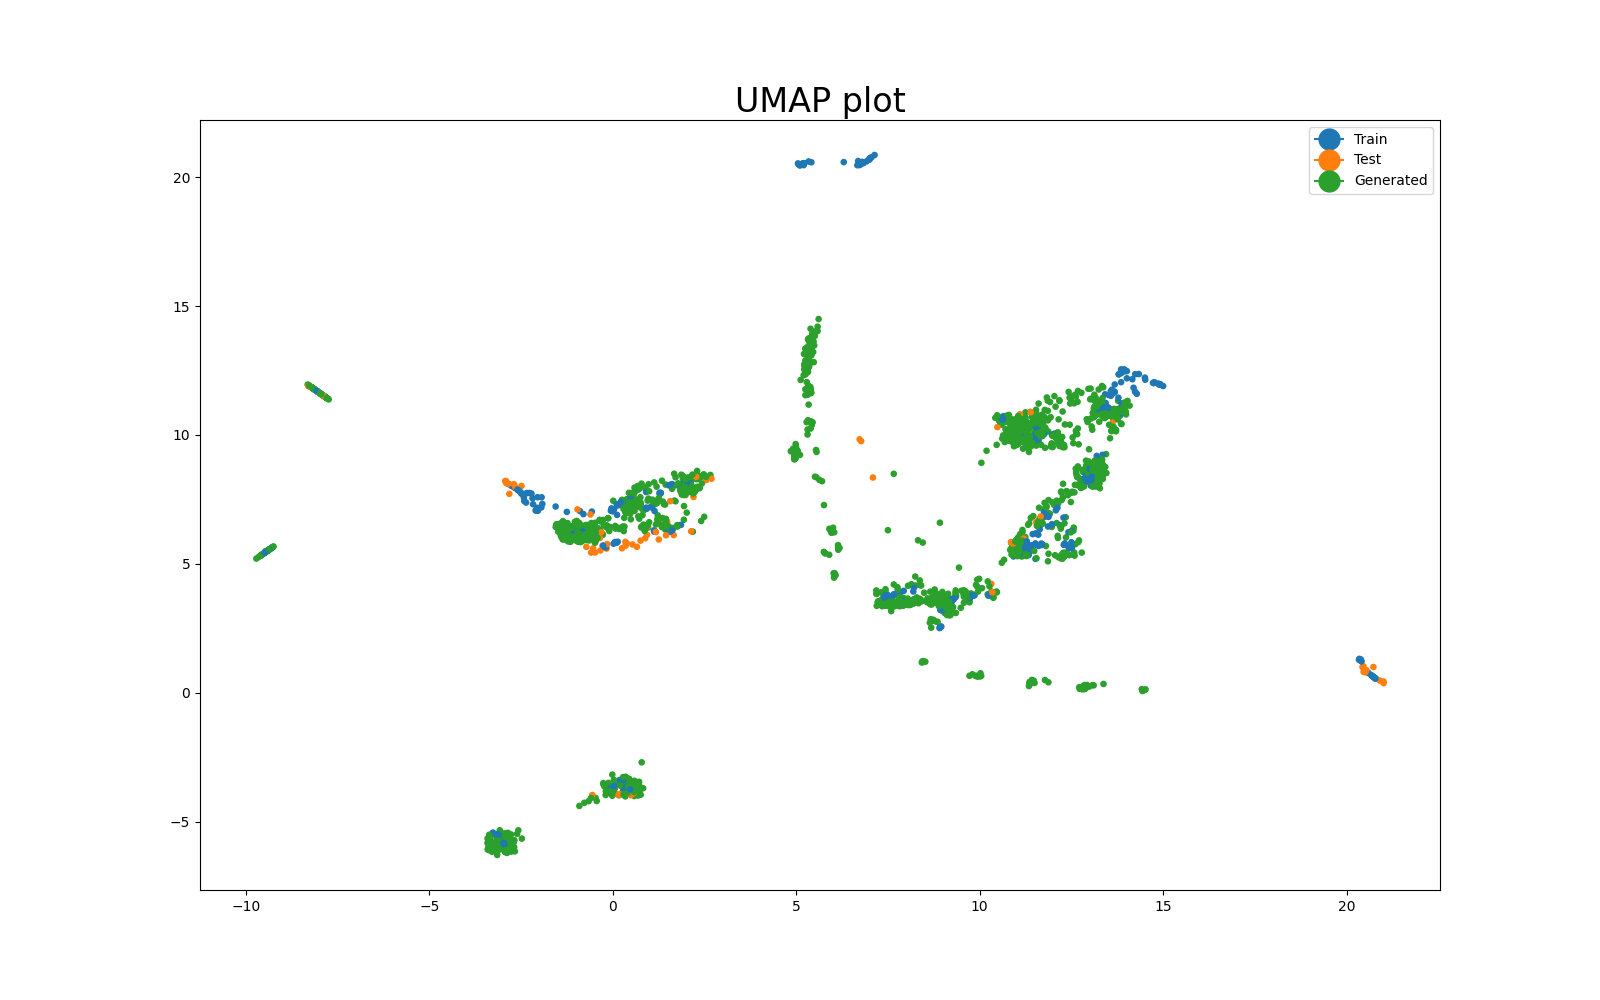

In [27]:
%matplotlib widget

def save_figure_to_file(fig, dir, filename):
    fig.savefig(dir + filename, format="png", bbox_inches='tight', transparent=False)

fig = make_scatter_plot_matplotlib(total_df)
save_figure_to_file(fig, MODEL_PATH_USED, "umap_matplotlib.png")

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
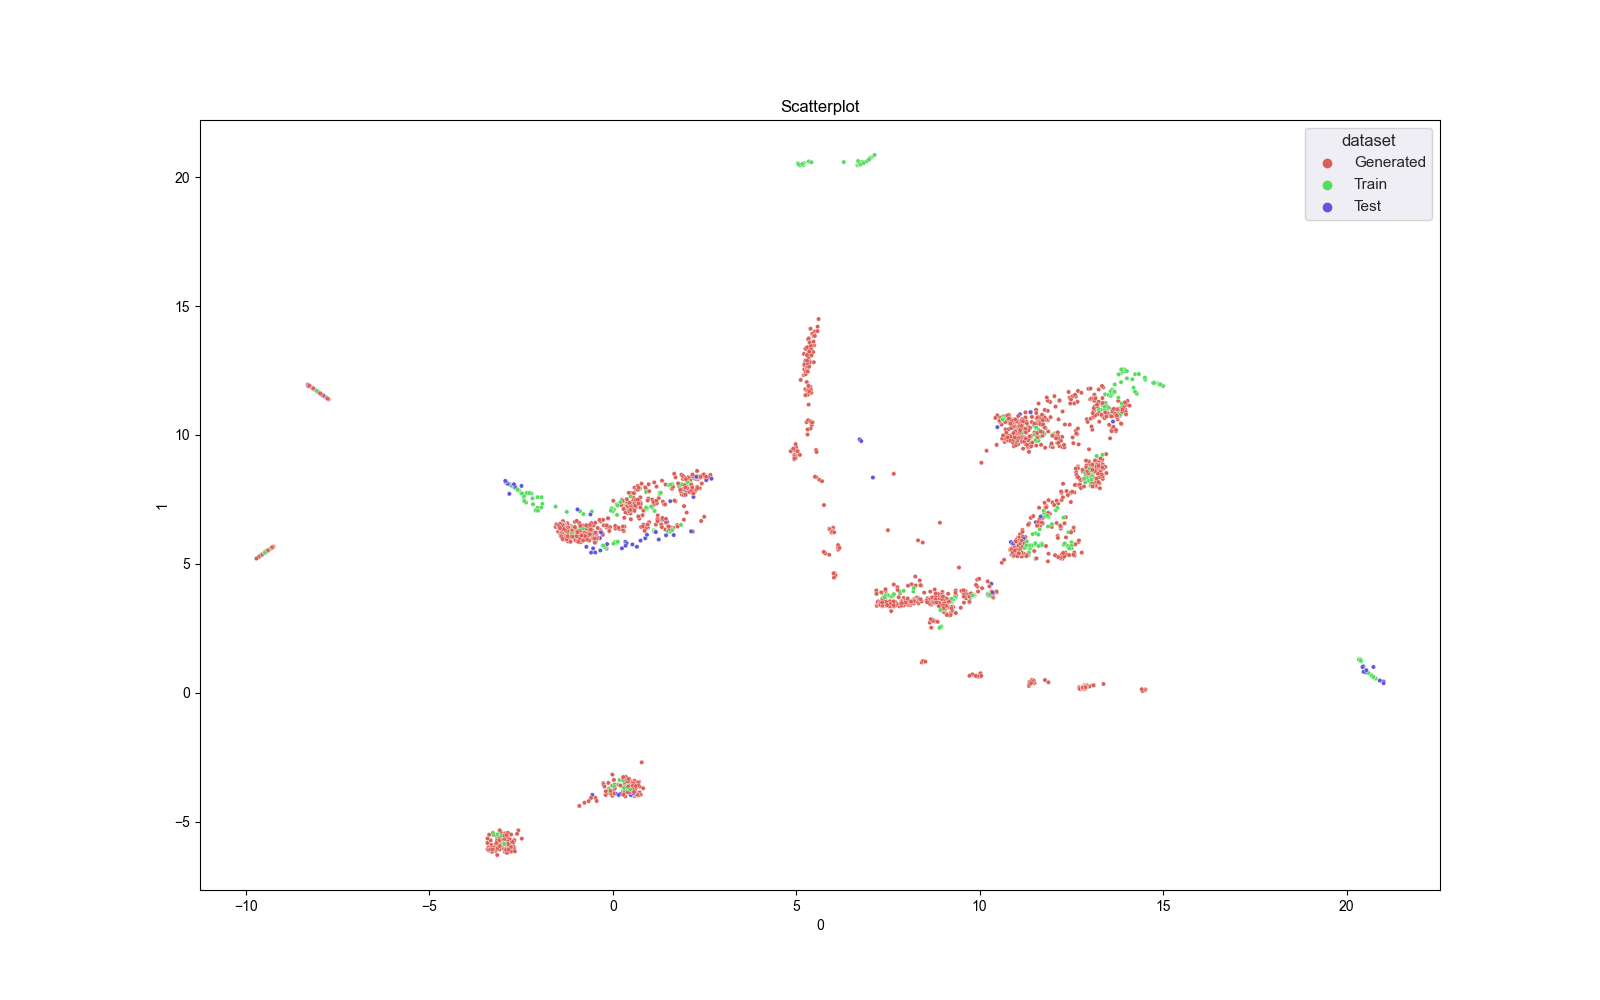

In [28]:
# using
fig = make_scatter_plot_sns(total_df)
save_figure_to_file(fig, MODEL_PATH_USED, "umap_seaborn.png")

## Cluster result image

In [29]:
#Import required module
from sklearn.cluster import KMeans

#Initialize the class object
kmeans = KMeans(n_clusters= 15)
df = total_df[[0, 1]].values
#predict the labels of clusters.
labels = kmeans.fit_predict(df)

unique_labels = list(set(labels))
len(labels), unique_labels

(2498, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14])

In [30]:
clustered_df = total_df.copy()
clustered_df['label'] = labels

In [31]:
clustered_df

,0,1,dataset,peptide,label
1498,-1.343822,6.453346,Generated,SLNKALYLL,1
1130,9.830274,3.802452,Generated,LLQCTNFMA,0
1722,0.542318,7.097067,Generated,VLLLNTVNV,12
42,8.954734,3.812896,Generated,ALFGLLVNF,0
182,14.195759,11.828951,Train,KMAAFPETL,3
...,...,...,...,...,...
337,0.592183,7.052288,Generated,FLGANLFGL,12
1114,9.569601,3.723884,Generated,LLNCYFFMV,0
517,9.000246,3.719996,Generated,FMNYDDSWL,0
613,13.889032,10.976377,Generated,GLPVYVFLA,3


# Plot clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
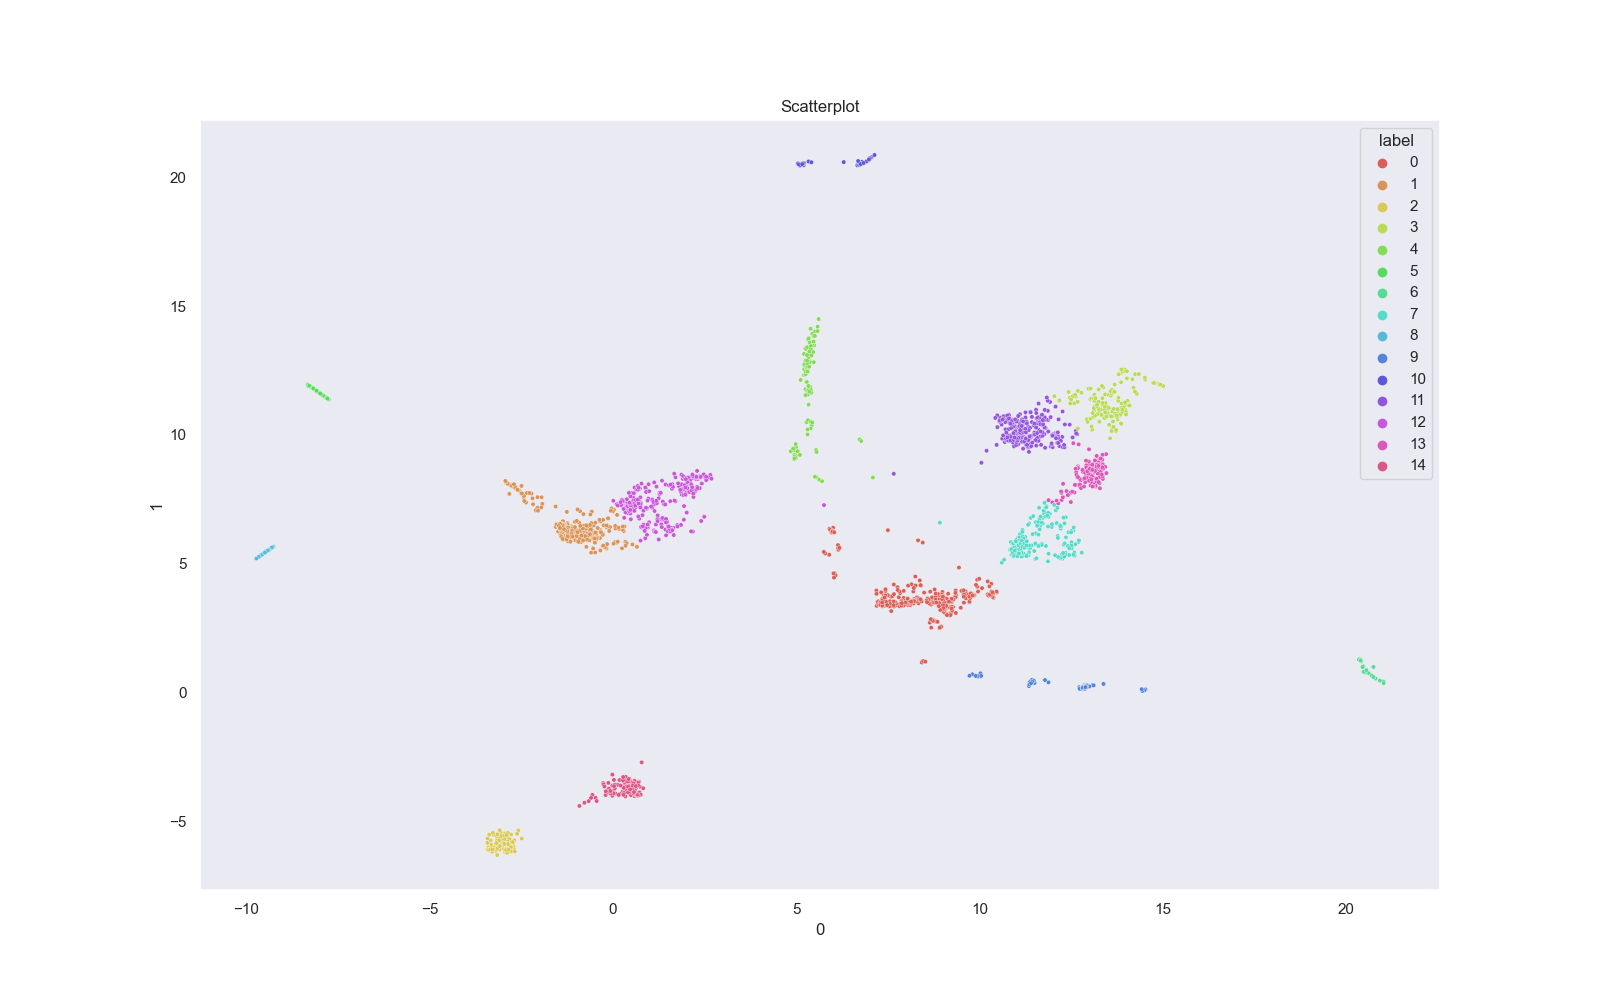

In [32]:
fig = make_scatter_plot_sns(clustered_df, hue_column='label')

save_figure_to_file(fig, MODEL_PATH_USED, "clustered_umap.png")

## Analyze clusters

In [33]:
clustered_df

,0,1,dataset,peptide,label
1498,-1.343822,6.453346,Generated,SLNKALYLL,1
1130,9.830274,3.802452,Generated,LLQCTNFMA,0
1722,0.542318,7.097067,Generated,VLLLNTVNV,12
42,8.954734,3.812896,Generated,ALFGLLVNF,0
182,14.195759,11.828951,Train,KMAAFPETL,3
...,...,...,...,...,...
337,0.592183,7.052288,Generated,FLGANLFGL,12
1114,9.569601,3.723884,Generated,LLNCYFFMV,0
517,9.000246,3.719996,Generated,FMNYDDSWL,0
613,13.889032,10.976377,Generated,GLPVYVFLA,3


In [34]:
import logomaker

def logo_pictures_for_clusters(source_clustered_df, per_dataset=False):
    if per_dataset:
        unique_datasets = set(source_clustered_df.dataset.values)
    else:
        unique_datasets = ["Whole"]
    unique_labels = set(source_clustered_df.label.values)
    fig, axes = plt.subplots(ncols=len(unique_datasets), nrows=len(unique_labels), figsize=[5*(len(unique_datasets)), 1*(len(unique_labels))])
    for cluster_index, cluster_label in enumerate(unique_labels):
        for dataset_index, dataset_type in enumerate(unique_datasets):
            if per_dataset:
                print(f" label {cluster_label} dataset {dataset_type}")
                peptides = source_clustered_df[(source_clustered_df['label'] == cluster_label) & (source_clustered_df['dataset'] == dataset_type)]['peptide'].values
            else:
                peptides = source_clustered_df[source_clustered_df['label'] == cluster_label]['peptide'].values
            ax = axes[cluster_index][dataset_index] if per_dataset else axes[cluster_index]
            if len(peptides) > 0:
                matrix = logomaker.alignment_to_matrix(peptides)
                info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
                # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
                ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=ax)
            ax.set_title(f"Cluster {cluster_label}, dataset {dataset_type}, size {len(peptides)}")
    plt.tight_layout()

    return fig


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
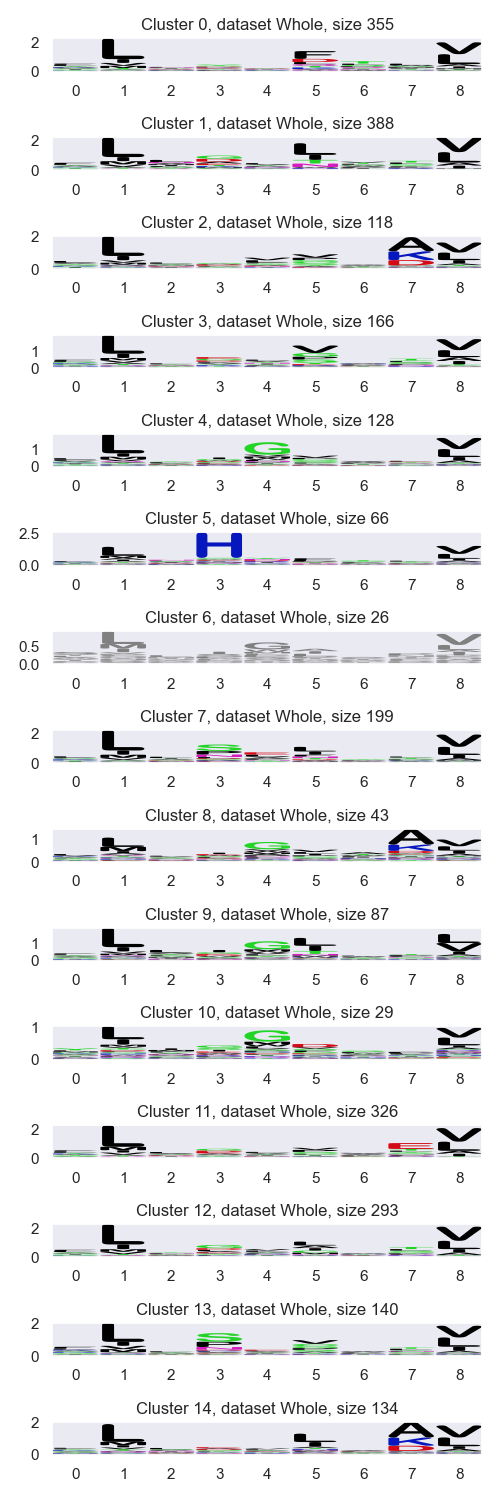

In [35]:
fig = logo_pictures_for_clusters(clustered_df)

 label 0 dataset Test
 label 0 dataset Train
 label 0 dataset Generated
 label 1 dataset Test
 label 1 dataset Train
 label 1 dataset Generated
 label 2 dataset Test
 label 2 dataset Train
 label 2 dataset Generated
 label 3 dataset Test
 label 3 dataset Train
 label 3 dataset Generated
 label 4 dataset Test
 label 4 dataset Train
 label 4 dataset Generated
 label 5 dataset Test
 label 5 dataset Train
 label 5 dataset Generated
 label 6 dataset Test
 label 6 dataset Train
 label 6 dataset Generated
 label 7 dataset Test
 label 7 dataset Train
 label 7 dataset Generated
 label 8 dataset Test
 label 8 dataset Train
 label 8 dataset Generated
 label 9 dataset Test
 label 9 dataset Train
 label 9 dataset Generated
 label 10 dataset Test
 label 10 dataset Train
 label 10 dataset Generated
 label 11 dataset Test
 label 11 dataset Train
 label 11 dataset Generated
 label 12 dataset Test
 label 12 dataset Train
 label 12 dataset Generated
 label 13 dataset Test
 label 13 dataset Train
 label 1

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
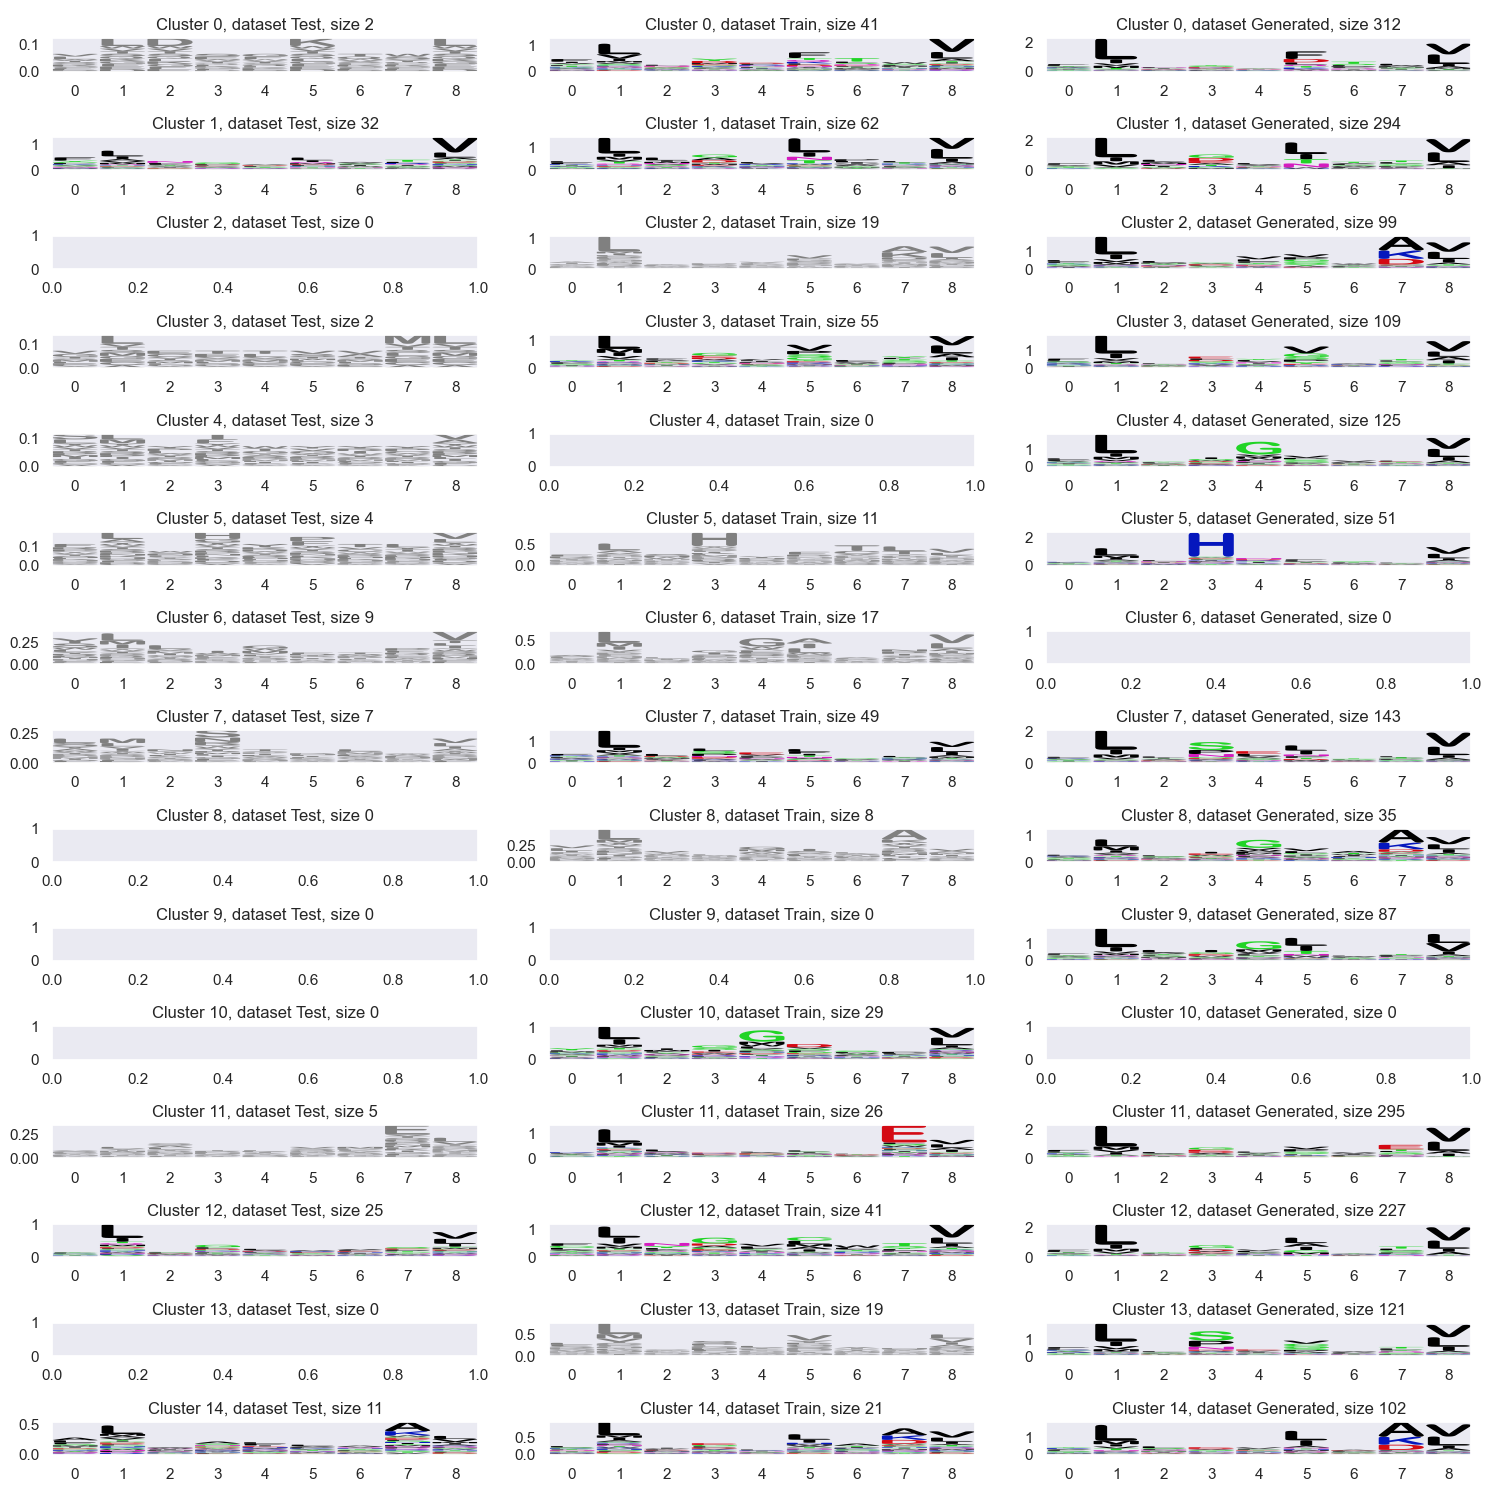

In [36]:
fig = logo_pictures_for_clusters(clustered_df, per_dataset=True)


# PCA

In [37]:
import sklearn
import seaborn as sns
from sklearn.decomposition import PCA


def get_pca(df_concat, n_components=2, target_col="dataset"):
    X = df_concat.drop(columns=target_col, errors='ignore').values
    pca = PCA(n_components=n_components)
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

def get_pca_embedding(pca, data, target_col="dataset"):
    X = data.drop(columns=target_col, errors='ignore').values
    pca_result = pca.transform(X)
    df = pd.DataFrame(pca_result)
    return df

In [38]:
pca = get_pca(pd.concat([train_pivot]))
train_embedding = get_pca_embedding(pca, train_pivot)
test_embedding = get_pca_embedding(pca, test_pivot)
generated_embedding = get_pca_embedding(pca, generated_pivot)

Explained variation per principal component: [0.62416857 0.27128623]


In [39]:
train_embedding_df = pd.DataFrame(train_embedding)
train_embedding_df['dataset'] = 'Train'
train_embedding_df['peptide'] = train_pivot.index.values

test_embedding_df = pd.DataFrame(test_embedding)
test_embedding_df['dataset'] = 'Test'
test_embedding_df['peptide'] = test_pivot.index.values

generated_embedding_df = pd.DataFrame(generated_embedding)
generated_embedding_df['dataset'] = 'Generated'
generated_embedding_df['peptide'] = generated_pivot.index.values


total_df = pd.concat([train_embedding_df,
                      test_embedding_df,
                      generated_embedding_df
                      ])
# total_pivot = pd.concat([train_pivot, test_pivot, generated_pivot])

total_df = total_df.sample(frac=1)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
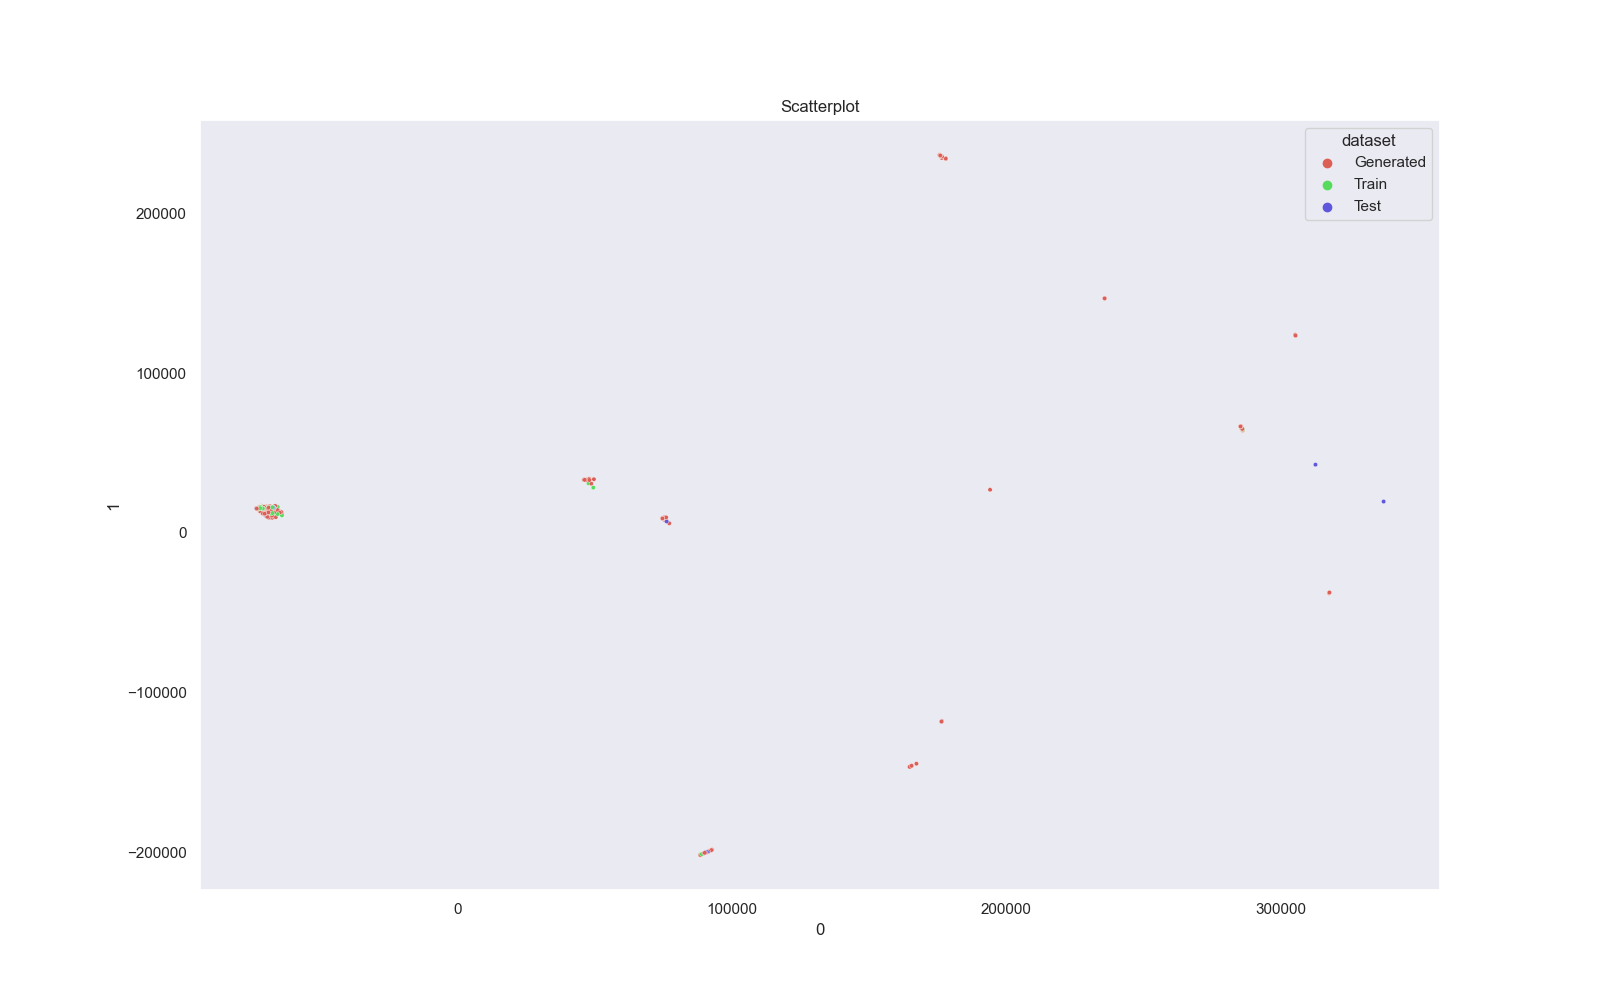

In [40]:
fig = make_scatter_plot_sns(total_df, hue_column='dataset')

save_figure_to_file(fig, TARGET_PATH_TO_RESULTS, "pca.png")

### Cluster PCA

In [41]:
#Import required module
from sklearn.cluster import KMeans

#Initialize the class object
kmeans = KMeans(n_clusters= 8)
df = total_df[[0, 1]].values
#predict the labels of clusters.
labels = kmeans.fit_predict(df)

unique_labels = list(set(labels))
len(labels), unique_labels

(2498, [0, 1, 2, 3, 4, 5, 6, 7])

In [42]:
clustered_df = total_df.copy()
clustered_df['label'] = labels

In [43]:
clustered_df

,0,1,dataset,peptide,label
700,285946.050231,65098.470605,Generated,IIIEEPVAV,4
1599,285413.198479,66442.905895,Generated,TLLEVIIAL,4
550,-72057.381036,14575.596321,Generated,GICGPLTYV,0
53,-71820.679806,13591.579974,Generated,ALHLPIFHV,0
164,-70039.780975,14832.473556,Train,KLCTFSFLI,0
...,...,...,...,...,...
686,89982.117884,-200430.632692,Generated,HLYWLYVSL,2
403,-73037.212571,15215.175794,Generated,FLNDVFMPL,0
326,-67715.887586,15982.302565,Train,TLWVDPYEV,0
57,-72153.536659,15442.959377,Train,FISDKIKFL,0


# check plot with clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
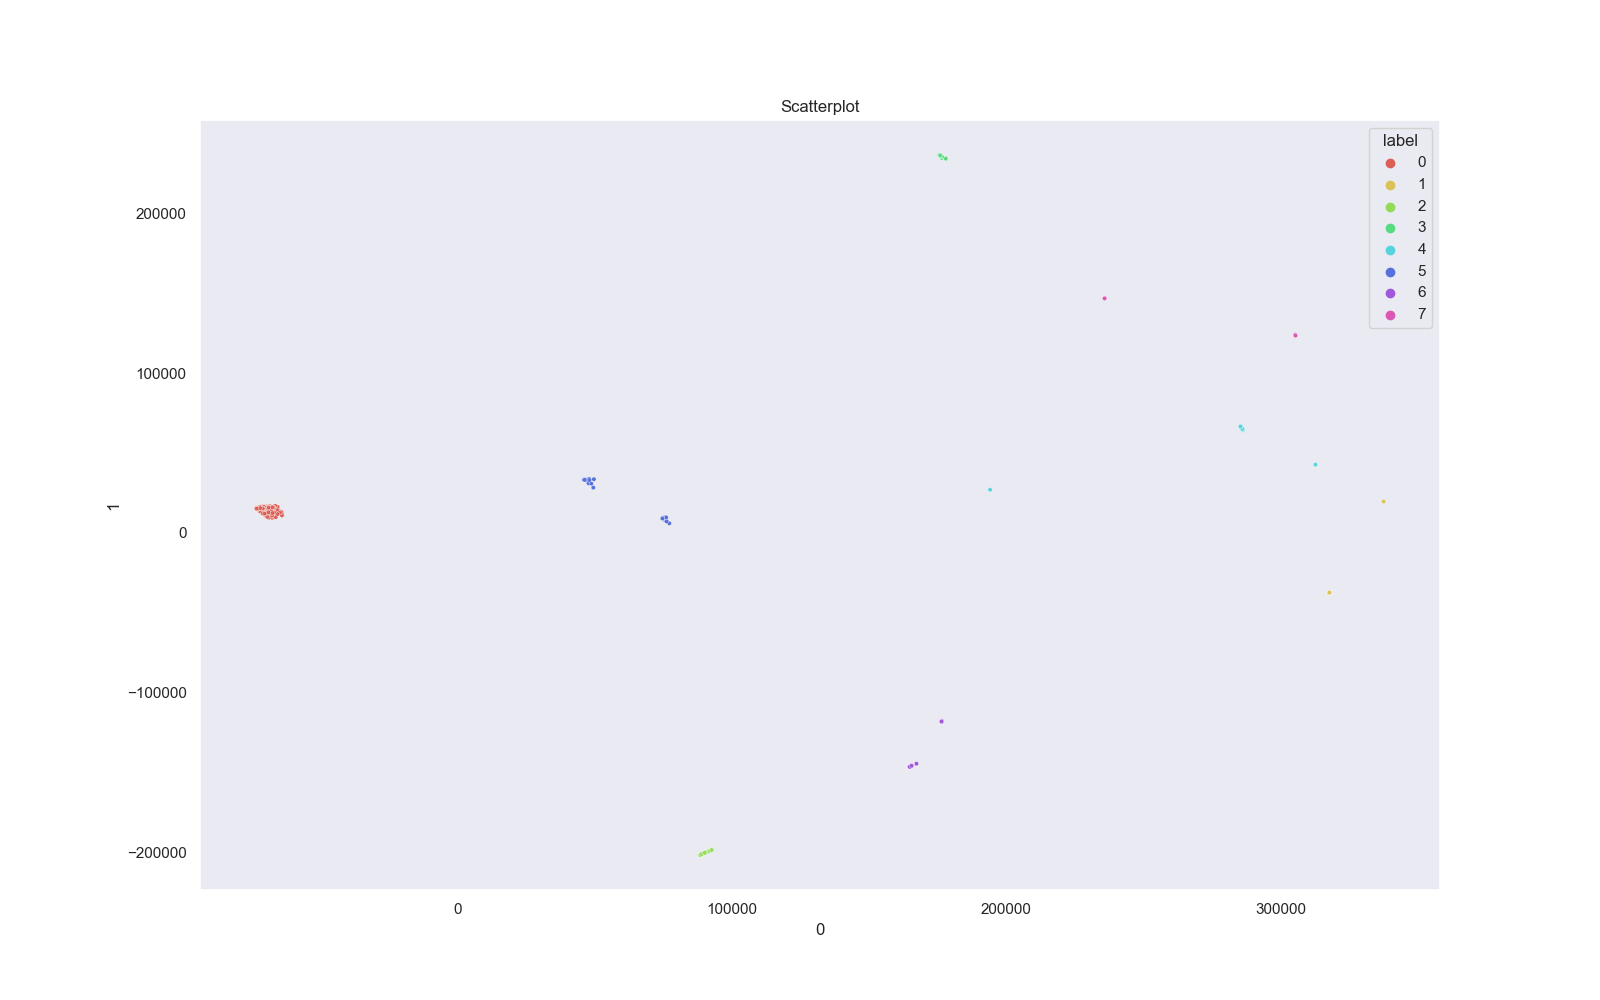

In [44]:
fig = make_scatter_plot_sns(clustered_df, hue_column='label')

save_figure_to_file(fig, MODEL_PATH_USED, "clustered_pca.png")


## Analyze clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
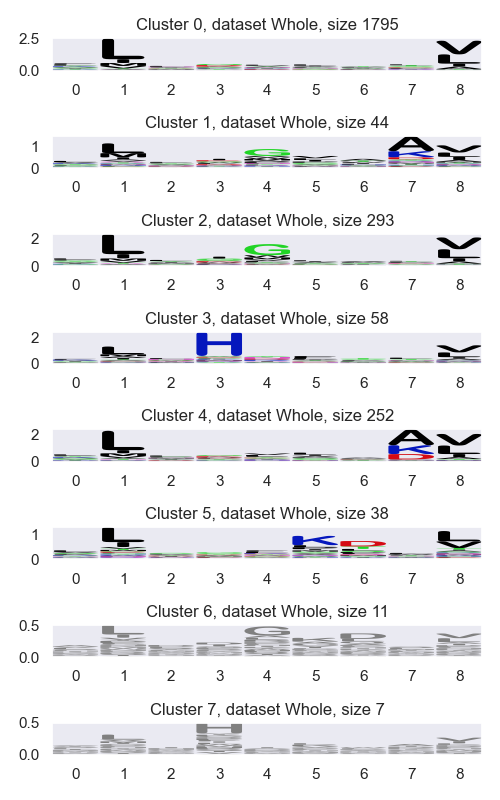

In [45]:
fig = logo_pictures_for_clusters(clustered_df)

# Cluster the original dataframe

In [46]:

train_pivot = train_pivot.drop(columns=["dataset"],errors='ignore')
test_pivot = test_pivot.drop(columns=["dataset"],errors='ignore')
generated_pivot = generated_pivot.drop(columns=["dataset"],errors='ignore')

train_pivot

path_index,0,1,2,3,4,5,6,7,8,9,...,80,81,82,83,84,85,86,87,88,89
peptide,,,,,,,,,,,,,,,,,,,,,
AIISGDSPV,-272.457265,-272.505763,-274.017186,-272.988212,-22.088429,-273.868460,-50000.000000,-50000.000000,-273.036710,-22.136927,...,-50000.000000,-33.458241,-50000.000000,-33.506738,-50000.000000,-35.018162,-33.989187,-50000.000000,-34.037685,-35.549108
AIMDKNIIL,-26.579728,-26.628226,-28.139649,-28.729201,-25.132798,-27.706977,-24.979278,-28.192856,-28.777699,-25.181296,...,-36.175261,-34.730971,-34.577452,-34.779469,-34.625950,-36.290893,-36.880445,-36.137373,-36.928943,-38.440366
AIMDKNIML,-706.095362,-706.143860,-707.655284,-708.244836,-25.472218,-707.222611,-25.318698,-707.708490,-708.293333,-25.520716,...,-36.514680,-35.070391,-34.916871,-35.118889,-34.965369,-36.630312,-37.219864,-36.476793,-37.268362,-38.779785
AINGVMWTV,-21.584196,-21.632694,-23.144117,-21.387307,-225.304725,-22.995391,-228.297796,-26.343915,-21.435805,-225.353223,...,-38.092174,-129.306207,-132.299278,-129.354705,-132.347776,-130.866128,-129.109318,-133.859199,-129.157815,-130.669239
AIYDTMQYV,-25.267935,-25.316433,-26.827856,-120.829951,-120.451800,-26.679130,-214.436089,-121.018872,-120.878449,-120.500297,...,-131.516258,-131.739072,-225.723361,-131.787570,-225.771859,-133.298993,-227.301088,-227.283283,-227.349586,-228.861009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YTMDGEYRL,-27.050329,-26.533246,-28.089343,-29.199802,-412.522769,-28.177578,-50000.000000,-50000.000000,-28.682720,-412.005686,...,-50000.000000,-422.736149,-50000.000000,-422.219067,-50000.000000,-423.775163,-424.885622,-50000.000000,-424.368540,-425.924636
YVDDVVLGA,-23.483206,-22.966124,-24.522220,-24.083950,-440.284168,-25.072082,-441.062994,-26.028679,-23.566868,-439.767086,...,-35.682189,-450.631365,-451.410191,-450.114282,-450.893108,-451.670379,-451.232109,-452.449205,-450.715026,-452.271123
YVLDHLIVV,-22.747243,-22.230160,-23.786257,-24.396370,-25.684296,-24.158437,-26.114789,-24.944383,-23.879288,-25.167213,...,-34.339357,-34.998523,-35.429016,-34.481441,-34.911934,-36.037537,-36.647651,-36.468030,-36.130568,-37.686665


In [47]:
#Import required module
from sklearn.cluster import KMeans

def cluster_data(predictor, source_df, dataset_name):
    labels = predictor.predict(source_df.values)
    result_df = source_df.copy()
    result_df['label'] = labels
    result_df['dataset'] = dataset_name
    return result_df
    
    

#Initialize the class object
kmeans = KMeans(n_clusters= 15)
df = train_pivot.values
#predict the labels of clusters.
kmeans.fit(df)


train_clustered = cluster_data(kmeans, train_pivot, "Train")
test_clustered = cluster_data(kmeans, test_pivot, "Test")
generated_clustered = cluster_data(kmeans, generated_pivot, "Generated")

total_clustered = pd.concat([train_clustered,test_clustered , generated_clustered])
labels = total_clustered['label']
unique_labels = list(set(labels))
len(labels), unique_labels

(2498, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14])

## Make UMAP again

In [48]:
train_embedding = get_umap_embedding(reducer, scaler, train_pivot)
test_embedding = get_umap_embedding(reducer, scaler, test_pivot)
generated_embedding = get_umap_embedding(reducer, scaler, generated_pivot)

In [49]:
train_embedding_df = pd.DataFrame(train_embedding)
train_embedding_df['dataset'] = train_clustered['dataset'].values
train_embedding_df['peptide'] = train_clustered.index.values
train_embedding_df['label'] = train_clustered['label'].values
test_embedding_df = pd.DataFrame(test_embedding)
test_embedding_df['dataset'] = test_clustered['dataset'].values
test_embedding_df['peptide'] = test_clustered.index.values
test_embedding_df['label'] = test_clustered['label'].values

generated_embedding_df = pd.DataFrame(generated_embedding)
generated_embedding_df['dataset'] = generated_clustered['dataset'].values
generated_embedding_df['peptide'] = generated_clustered.index.values
generated_embedding_df['label'] = generated_clustered['label'].values
total_df = pd.concat([train_embedding_df,
                      test_embedding_df,
                      generated_embedding_df
                      ])
# total_pivot = pd.concat([train_pivot, test_pivot, generated_pivot])

total_df = total_df.sample(frac=1)

In [50]:
total_df

,0,1,dataset,peptide,label
151,1.092937,7.502289,Generated,ATNGSMATV,7
191,8.294352,3.597182,Generated,CLNKHDFPV,13
680,9.000175,3.515458,Generated,HLMDYFSWL,13
248,5.822394,5.439610,Generated,FIDSMLQWI,3
283,1.530834,8.043953,Train,SIYVYALPL,8
...,...,...,...,...,...
699,-1.340840,6.475389,Generated,IIDKYLASA,7
37,2.163074,8.301303,Test,HLSLRGLPV,14
593,12.823380,0.175078,Generated,GLLILLLHL,3
1867,5.276638,11.618918,Generated,YLFVGPVRL,12


Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
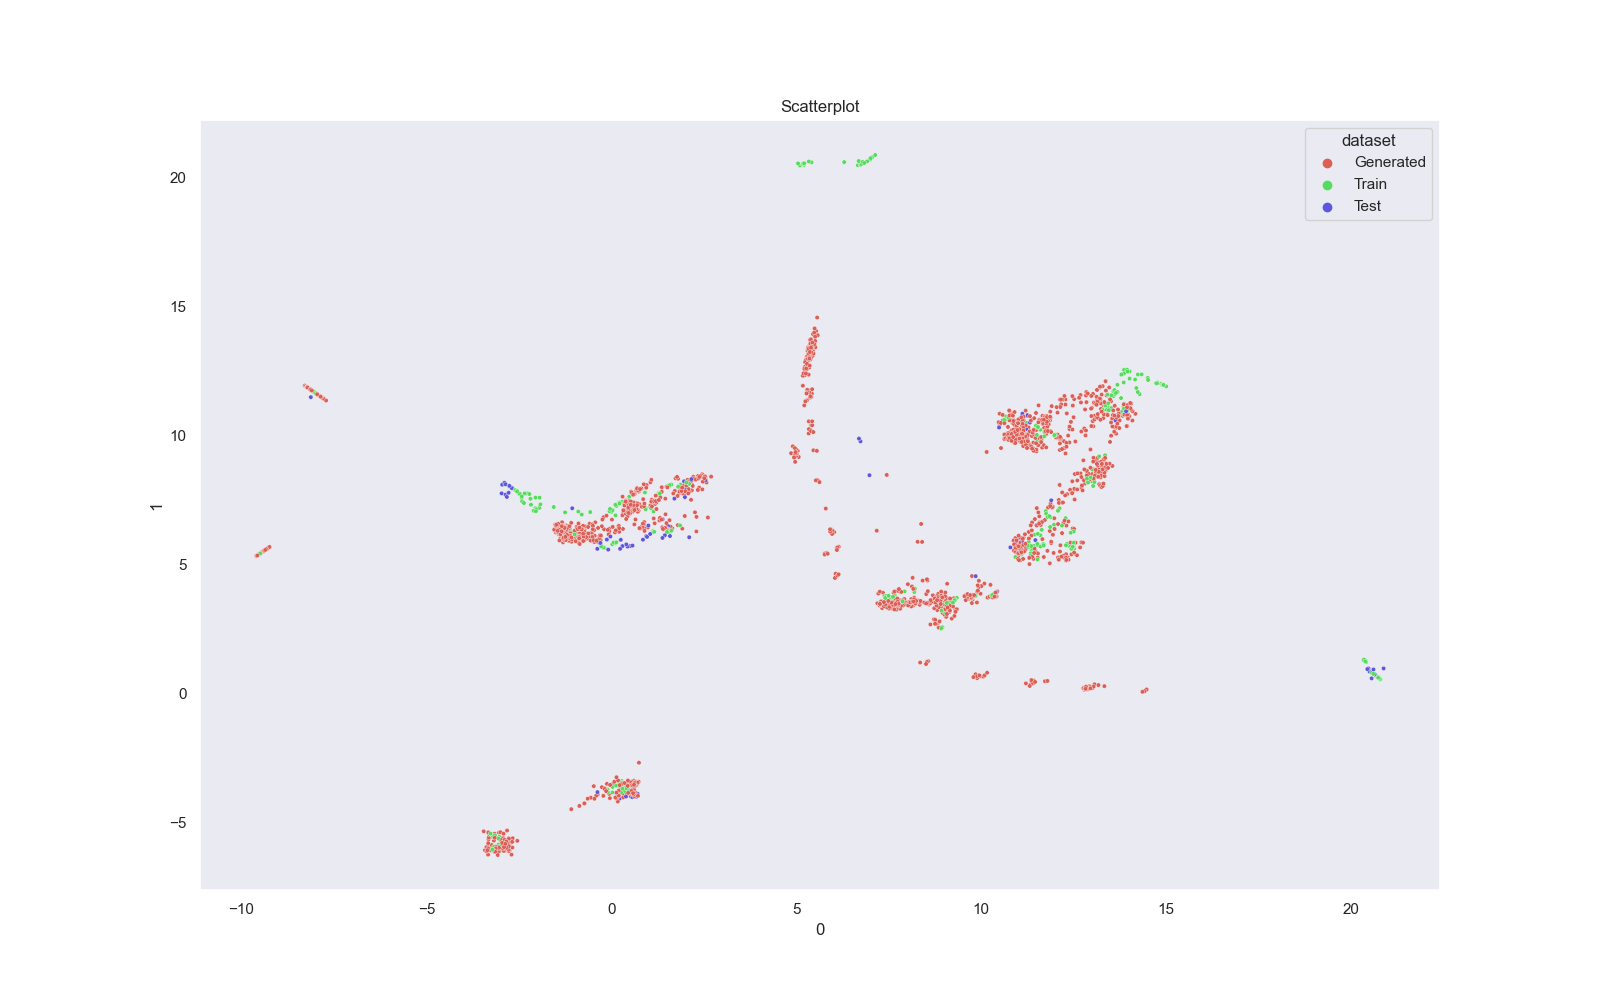

In [51]:
fig = make_scatter_plot_sns(total_df, hue_column='dataset')

save_figure_to_file(fig, TARGET_PATH_TO_RESULTS, "umap_after_clustering.png")

## Color by initial cluster

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
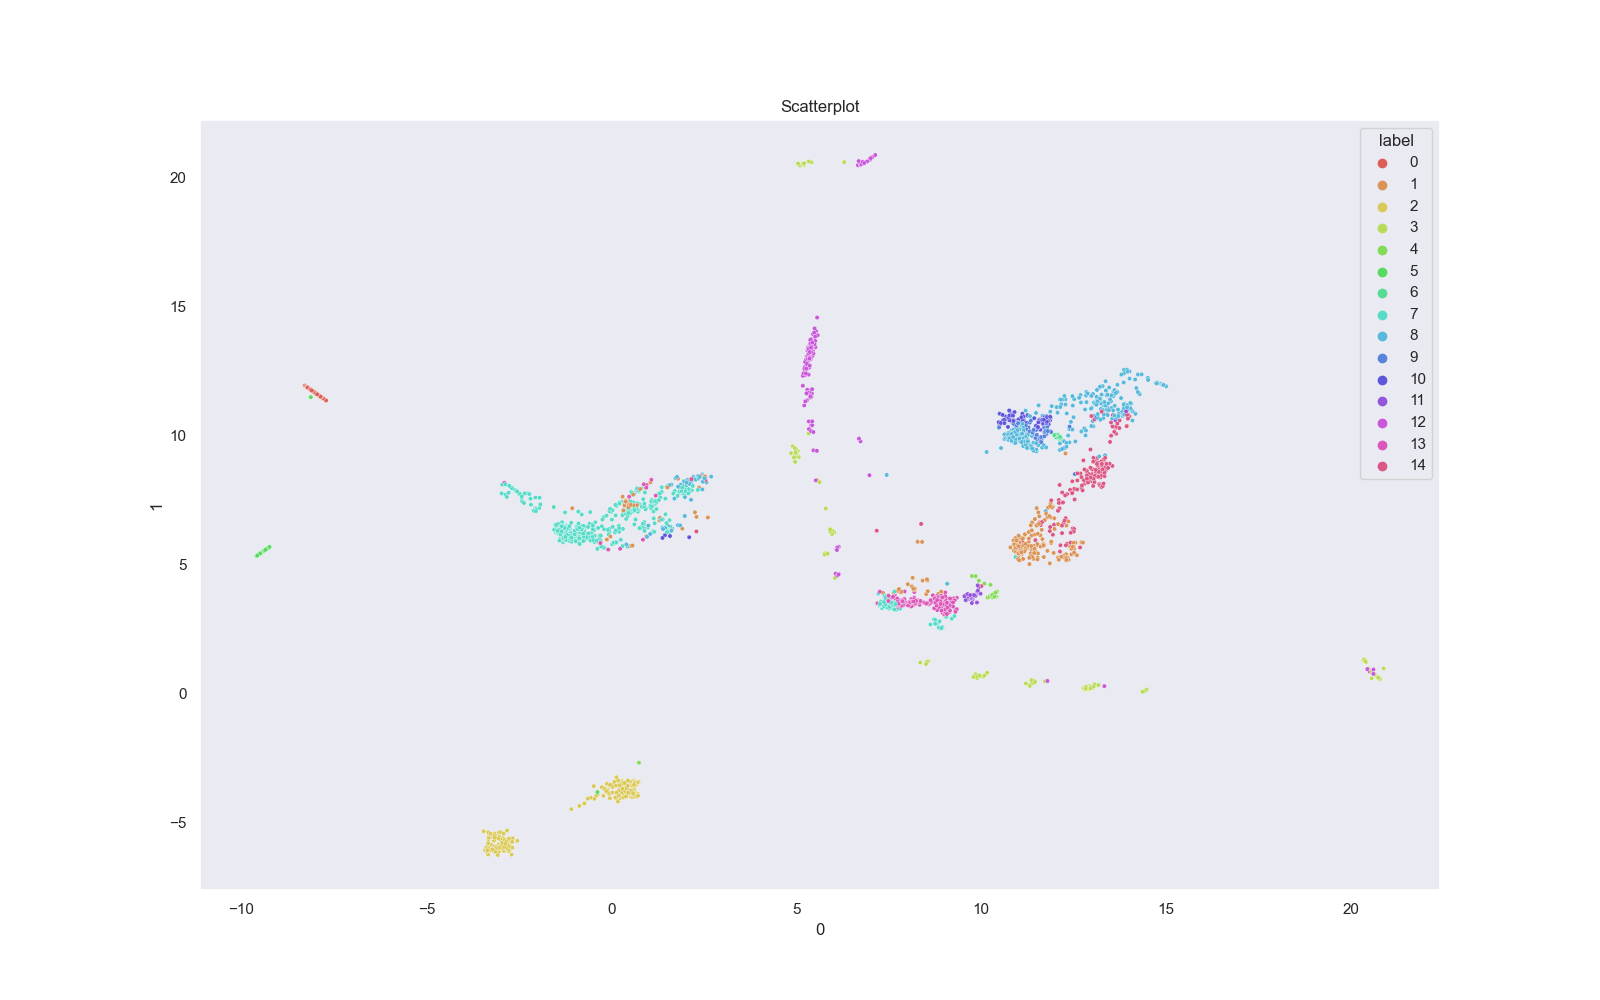

In [52]:
fig = make_scatter_plot_sns(total_df, hue_column='label')

save_figure_to_file(fig, TARGET_PATH_TO_RESULTS, "clustered_umap_after_clustering.png")

## Analyze clusters

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
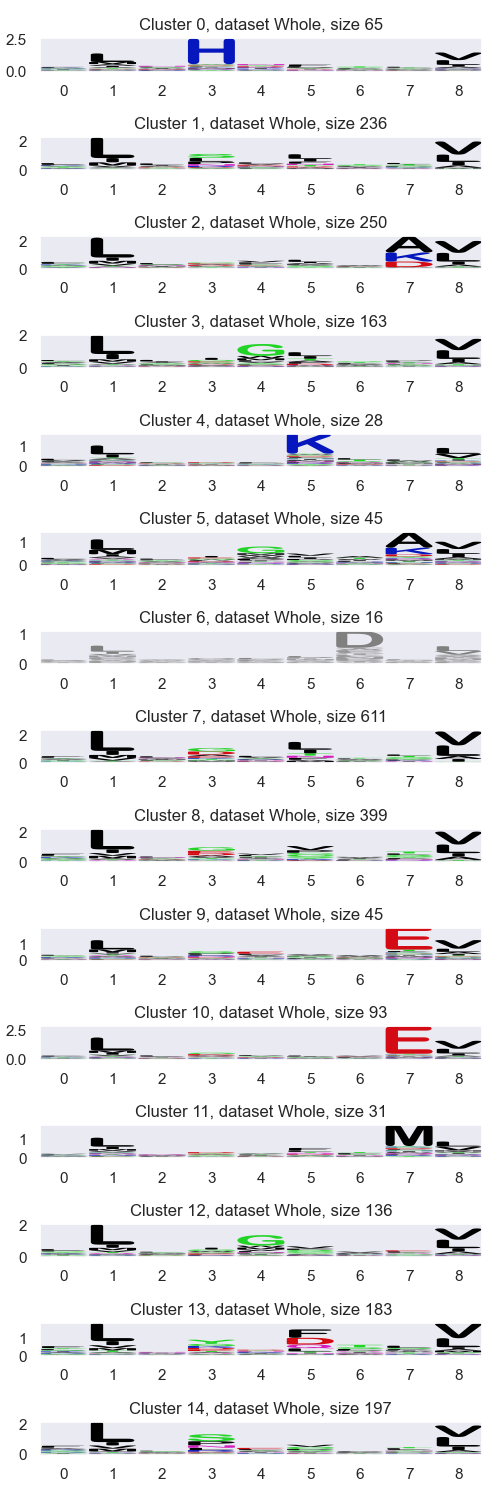

In [53]:
fig = logo_pictures_for_clusters(total_df)

 label 0 dataset Test
 label 0 dataset Train
 label 0 dataset Generated
 label 1 dataset Test
 label 1 dataset Train
 label 1 dataset Generated
 label 2 dataset Test
 label 2 dataset Train
 label 2 dataset Generated
 label 3 dataset Test
 label 3 dataset Train
 label 3 dataset Generated
 label 4 dataset Test
 label 4 dataset Train
 label 4 dataset Generated
 label 5 dataset Test
 label 5 dataset Train
 label 5 dataset Generated
 label 6 dataset Test
 label 6 dataset Train
 label 6 dataset Generated
 label 7 dataset Test
 label 7 dataset Train
 label 7 dataset Generated
 label 8 dataset Test
 label 8 dataset Train
 label 8 dataset Generated
 label 9 dataset Test
 label 9 dataset Train
 label 9 dataset Generated
 label 10 dataset Test
 label 10 dataset Train
 label 10 dataset Generated
 label 11 dataset Test
 label 11 dataset Train
 label 11 dataset Generated
 label 12 dataset Test
 label 12 dataset Train
 label 12 dataset Generated
 label 13 dataset Test
 label 13 dataset Train
 label 1

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
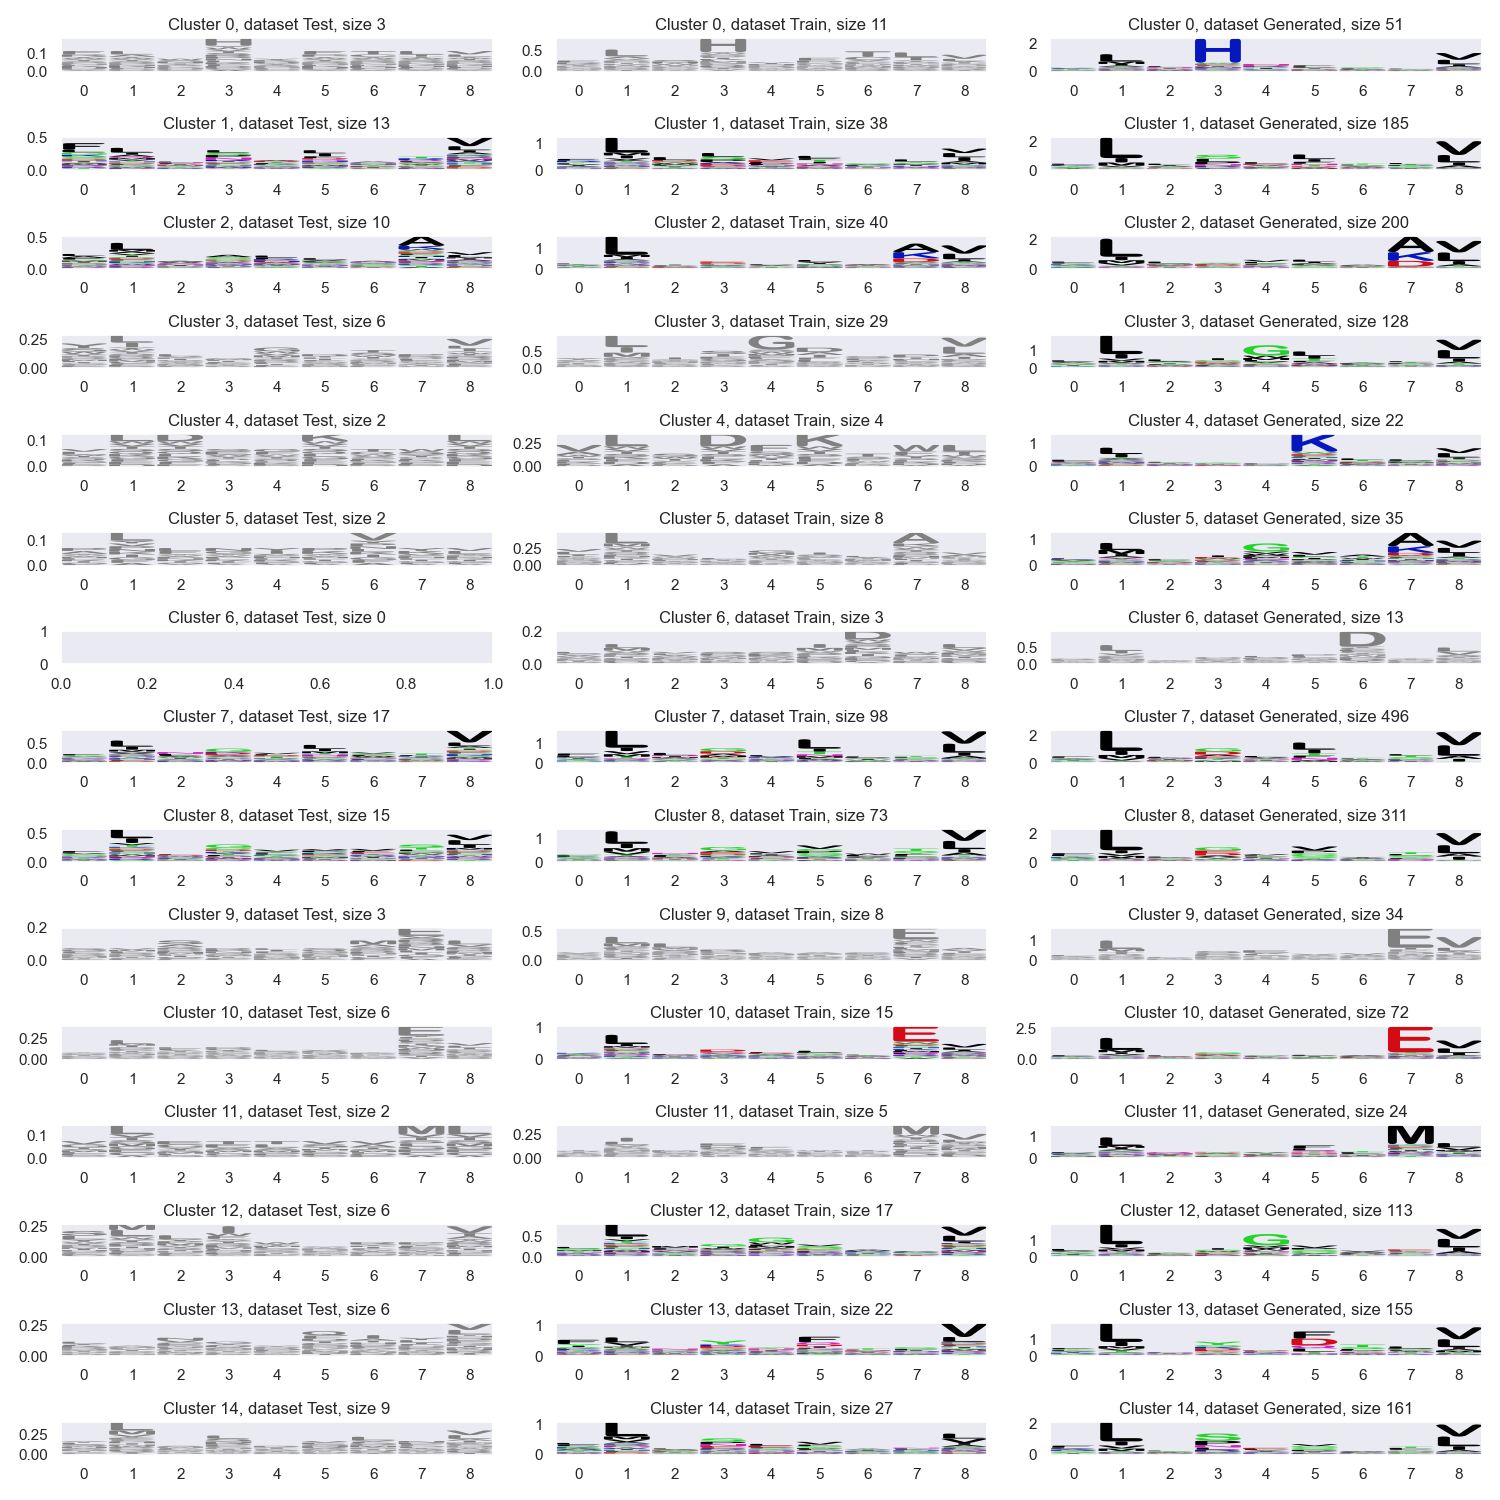

In [54]:
fig = logo_pictures_for_clusters(total_df, per_dataset=True)

# Same for PCA

In [55]:
train_embedding = get_pca_embedding(pca, train_pivot)
test_embedding = get_pca_embedding(pca, test_pivot)
generated_embedding = get_pca_embedding(pca, generated_pivot)

In [56]:
train_embedding_df = pd.DataFrame(train_embedding)
train_embedding_df['dataset'] = train_clustered['dataset'].values
train_embedding_df['peptide'] = train_clustered.index.values
train_embedding_df['label'] = train_clustered['label'].values
test_embedding_df = pd.DataFrame(test_embedding)
test_embedding_df['dataset'] = test_clustered['dataset'].values
test_embedding_df['peptide'] = test_clustered.index.values
test_embedding_df['label'] = test_clustered['label'].values

generated_embedding_df = pd.DataFrame(generated_embedding)
generated_embedding_df['dataset'] = generated_clustered['dataset'].values
generated_embedding_df['peptide'] = generated_clustered.index.values
generated_embedding_df['label'] = generated_clustered['label'].values
total_df = pd.concat([train_embedding_df,
                      test_embedding_df,
                      generated_embedding_df
                      ])
# total_pivot = pd.concat([train_pivot, test_pivot, generated_pivot])

total_df = total_df.sample(frac=1)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous …
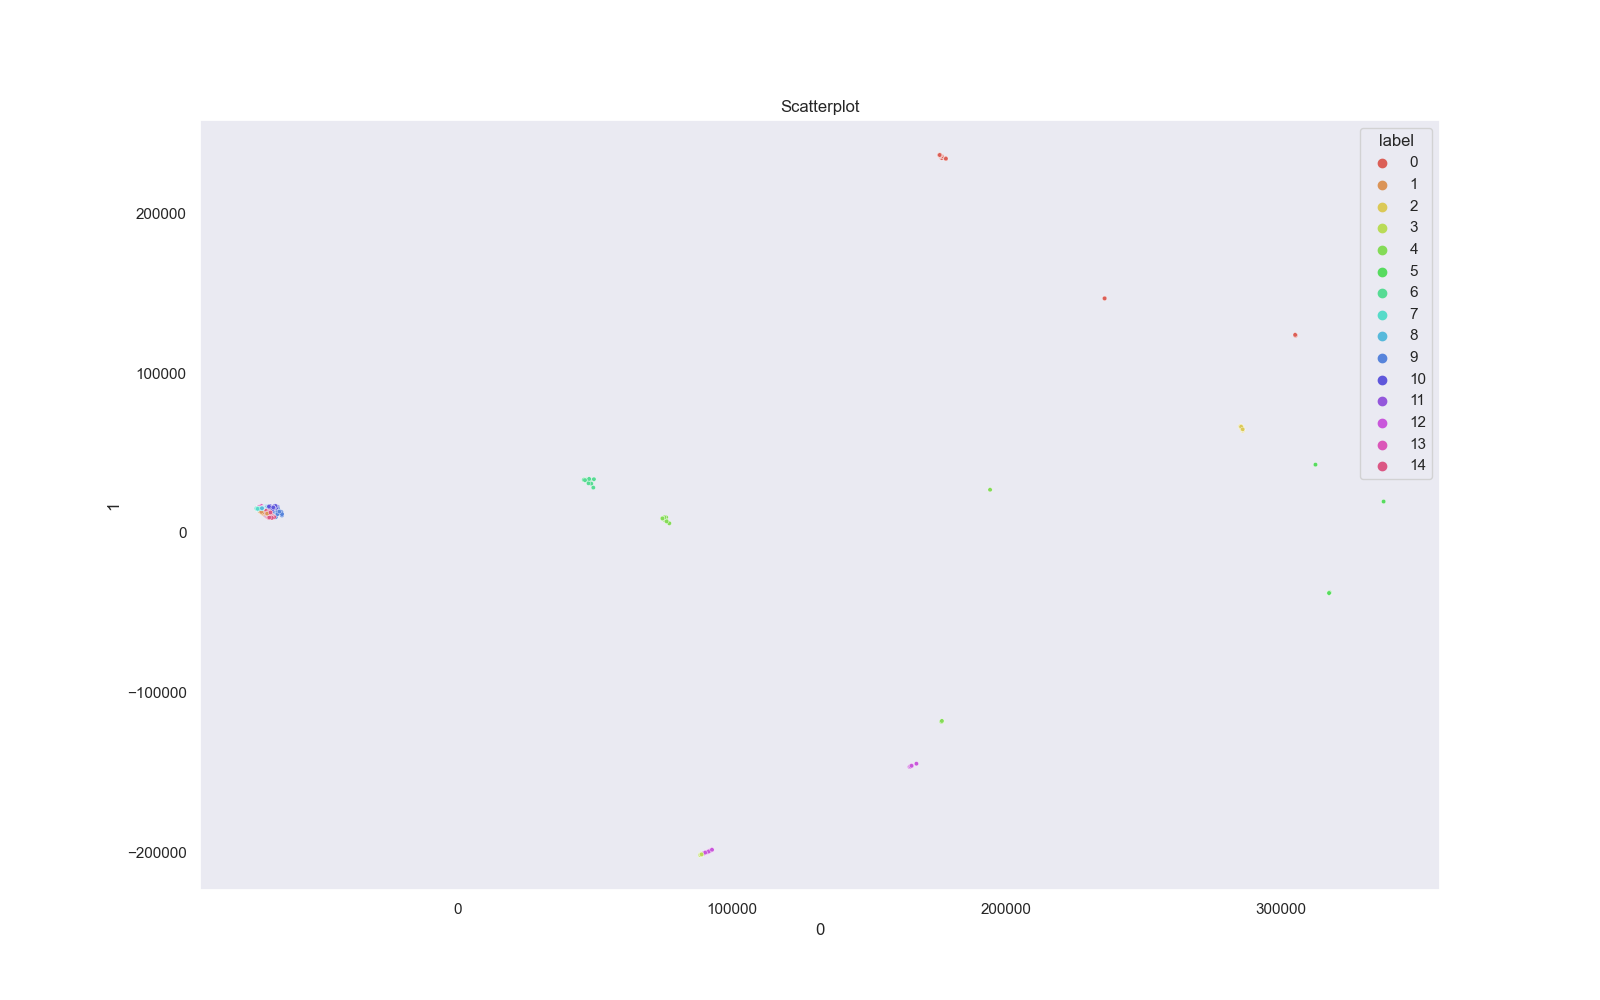

In [57]:
fig = make_scatter_plot_sns(total_df, hue_column='label')

save_figure_to_file(fig, TARGET_PATH_TO_RESULTS, "clustered_pca_after_clustering.png")

In [58]:
train_pivot_plus = train_pivot.copy()
train_pivot_plus['dataset'] = "Train"
test_pivot_plus = test_pivot.copy()
test_pivot_plus['dataset'] = "Test"

generated_pivot_plus = generated_pivot.copy()
generated_pivot_plus['dataset'] = "Generated"
total_pivot_plus = pd.concat([train_pivot_plus, test_pivot_plus, generated_pivot_plus])

In [59]:
for i in range(8):
    total_pivot_plus[f'a{i}'] = total_pivot_plus.index.str[i]

In [60]:
aa_columns = [f"a{i}" for i in range(8)]
total_pivot_plus[['dataset'] + aa_columns + [col for col in total_pivot_plus.columns if col != 'dataset' and col not in aa_columns]].to_csv(f'{MODEL_PATH_USED}/embedding.csv',sep="\t", index=True)

In [61]:
total_pivot_plus

path_index,0,1,2,3,4,5,6,7,8,9,...,89,dataset,a0,a1,a2,a3,a4,a5,a6,a7
peptide,,,,,,,,,,,,,,,,,,,,,
AIISGDSPV,-272.457265,-272.505763,-274.017186,-272.988212,-22.088429,-273.868460,-50000.000000,-50000.000000,-273.036710,-22.136927,...,-35.549108,Train,A,I,I,S,G,D,S,P
AIMDKNIIL,-26.579728,-26.628226,-28.139649,-28.729201,-25.132798,-27.706977,-24.979278,-28.192856,-28.777699,-25.181296,...,-38.440366,Train,A,I,M,D,K,N,I,I
AIMDKNIML,-706.095362,-706.143860,-707.655284,-708.244836,-25.472218,-707.222611,-25.318698,-707.708490,-708.293333,-25.520716,...,-38.779785,Train,A,I,M,D,K,N,I,M
AINGVMWTV,-21.584196,-21.632694,-23.144117,-21.387307,-225.304725,-22.995391,-228.297796,-26.343915,-21.435805,-225.353223,...,-130.669239,Train,A,I,N,G,V,M,W,T
AIYDTMQYV,-25.267935,-25.316433,-26.827856,-120.829951,-120.451800,-26.679130,-214.436089,-121.018872,-120.878449,-120.500297,...,-228.861009,Train,A,I,Y,D,T,M,Q,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YVVEGLENI,-23.259531,-22.742448,-24.298545,-75.448409,-316.195038,-25.629776,-50000.000000,-50000.000000,-74.931326,-315.677955,...,-89.204921,Generated,Y,V,V,E,G,L,E,N
YVVFVAHGV,-24.809990,-24.292908,-25.849004,-76.998869,-504.808755,-26.221185,-839.241839,-361.009722,-76.481786,-504.291672,...,-265.055448,Generated,Y,V,V,F,V,A,H,G
YVWMYIQGI,-72.347523,-71.830440,-73.386537,-28.303523,-84.798289,-74.717767,-37.138472,-26.454353,-27.786441,-84.281207,...,-52.121526,Generated,Y,V,W,M,Y,I,Q,G
